In [1]:
%pip install mlxtend

In [2]:
pip install seaborn

In [3]:
import numpy as np
import pandas as pd
import mlxtend as mx
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from sklearn.datasets import load_iris

In [5]:


iris_df = load_iris(as_frame=True)

df = iris_df.frame

In [6]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [7]:
df.isnull().mean()*100

,0
sepal length (cm),0.0
sepal width (cm),0.0
petal length (cm),0.0
petal width (cm),0.0
target,0.0


In [8]:
df.duplicated().sum()

np.int64(1)

In [9]:
df.drop_duplicates()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV

In [11]:
X=df.drop('target',axis=1)
y=df['target']

In [12]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [13]:
MODEL=RandomForestClassifier()

In [14]:
param_grid = {
    'n_estimators': [10,20,50,100,200],
    "criterion":["gini", "entropy" , "log_loss"],
    "max_depth":[10,20,50,100,]

}

grid=GridSearchCV(estimator=MODEL,param_grid=param_grid,cv=5,scoring='accuracy')

In [15]:
grid.fit(X_train, y_train)


GridSearchCV(cv=5, estimator=RandomForestClassifier(),
             param_grid={'criterion': ['gini', 'entropy', 'log_loss'],
                         'max_depth': [10, 20, 50, 100],
                         'n_estimators': [10, 20, 50, 100, 200]},
             scoring='accuracy')

In [16]:
print(grid.best_params_)
print(grid.best_score_)


{'criterion': 'entropy', 'max_depth': 50, 'n_estimators': 20}
0.9583333333333334


In [17]:
from mlxtend.plotting import plot_decision_regions

In [18]:
X = X.to_numpy()
y = y.to_numpy()

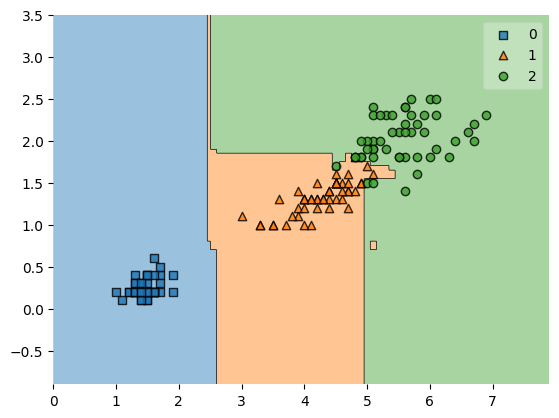

In [20]:
X = df[['petal length (cm)', 'petal width (cm)']].to_numpy()
y = df['target'].to_numpy().astype(int)

grid.fit(X, y)

plot_decision_regions(X, y, clf=grid)
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


ValueError: X has 4 features, but RandomForestClassifier is expecting 2 features as input.